# Transformaciones de Intensidad en Imágenes

**Curso:** Visión por Computador
**Actividad:** Transformaciones puntuales (lineales y no lineales) sobre imágenes en escala de grises y en color (RGB).

En este notebook se desarrollan los 15 ejercicios propuestos. Las funciones
matemáticas (transformación lineal, gamma, por canal, etc.) están definidas
en `transforms.py` para mantener este notebook enfocado en los resultados
y su interpretación. Más detalles del proyecto en el `README.md`.


In [1]:
# Importamos librerías y las funciones que hicimos en transforms.py
import numpy as np
import matplotlib.pyplot as plt

from transforms import (
    leer_gris, leer_color, mostrar_par, mostrar_imagen_e_histograma,
    histograma_gris, histogramas_rgb,
    transform_lineal, transform_piecewise, invertir, correccion_gamma,
    transform_lineal_por_canal, transform_canal_unico, eliminar_canal,
    gamma_por_canal, intercambiar_canales, a_escala_grises,
)

# Imágenes de trabajo (ver README para su origen)
img_gris = leer_gris("images/foto_gris.jpg")        # escala de grises normal
img_oscura = leer_gris("images/foto_oscura.jpg")    # versión oscura, para gamma
img_color = leer_color("images/foto_color.jpg")     # imagen a color (RGB)

print("Gris:", img_gris.shape, img_gris.dtype)
print("Oscura:", img_oscura.shape, "brillo promedio:", img_oscura.mean())
print("Color:", img_color.shape, img_color.dtype)


Gris: (512, 512) uint8
Oscura: (512, 512) brillo promedio: 44.6932373046875
Color: (512, 512, 3) uint8


# Parte 1: Transformaciones lineales (escala de grises)

## Ejercicio 1: Transformación lineal básica

$$I' = aI + b$$

Probamos 3 combinaciones de (a, b) sobre la imagen en escala de grises.


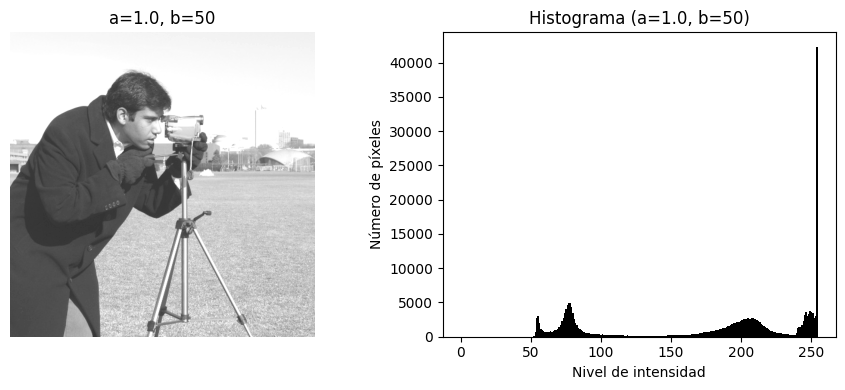

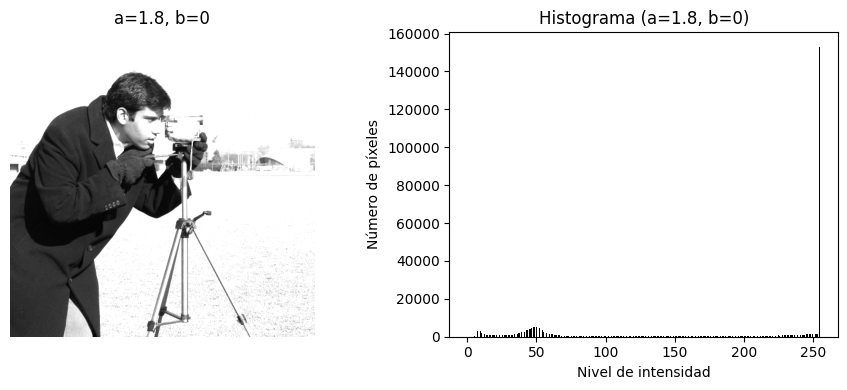

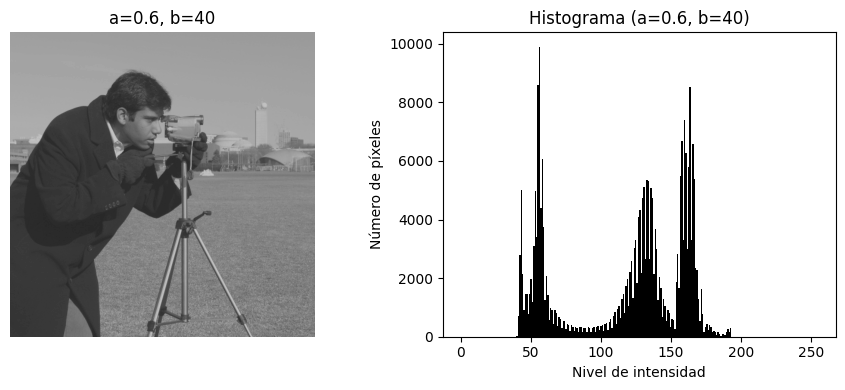

In [2]:
combinaciones = [
    (1.0, 50),   # solo sube el brillo
    (1.8, 0),    # solo sube el contraste
    (0.6, 40),   # baja contraste y sube un poco el brillo
]

for a, b in combinaciones:
    resultado = transform_lineal(img_gris, a=a, b=b, modo="clip")
    mostrar_imagen_e_histograma(
        resultado, cmap="gray",
        titulo_img=f"a={a}, b={b}",
        titulo_hist=f"Histograma (a={a}, b={b})",
    )


**Interpretación:**

- El parámetro **a** controla el **contraste**: con `a > 1` los tonos se
  separan más entre sí (más contraste), y con `a < 1` los tonos se acercan
  entre sí (imagen más "plana", menos contraste).
- El parámetro **b** controla el **brillo**: sumar un valor positivo
  desplaza todo el histograma hacia la derecha (imagen más clara), y un
  valor negativo lo desplazaría hacia la izquierda (imagen más oscura).


## Ejercicio 2: Saturación de valores

Cuando `a*I + b` sale del rango [0, 255], hay dos formas comunes de
manejarlo: **clipping** (recortar a 0 o 255) o **normalización** (reescalar
toda la imagen para que quepa en el rango).


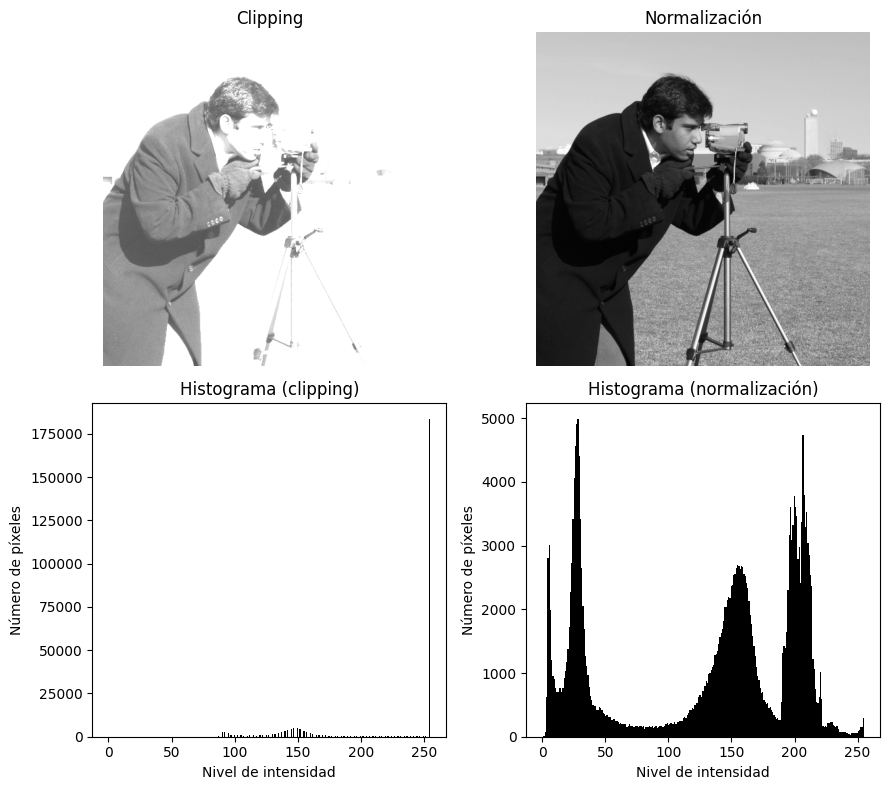

In [3]:
a, b = 2.5, 80  # a propósito genera muchos valores fuera de [0,255]

img_clip = transform_lineal(img_gris, a=a, b=b, modo="clip")
img_norm = transform_lineal(img_gris, a=a, b=b, modo="normalizar")

fig, ax = plt.subplots(2, 2, figsize=(9, 8))
ax[0,0].imshow(img_clip, cmap="gray", vmin=0, vmax=255); ax[0,0].set_title("Clipping"); ax[0,0].axis("off")
ax[0,1].imshow(img_norm, cmap="gray", vmin=0, vmax=255); ax[0,1].set_title("Normalización"); ax[0,1].axis("off")
histograma_gris(img_clip, ax=ax[1,0], titulo="Histograma (clipping)")
histograma_gris(img_norm, ax=ax[1,1], titulo="Histograma (normalización)")
plt.tight_layout()
plt.show()


**Interpretación:**

Con **clipping**, todos los valores que superan 255 quedan "pegados" en
255 (y los negativos en 0): eso genera un pico artificial en los extremos
del histograma y se **pierde información** — muchos píxeles distintos
terminan con el mismo valor (255), así que ya no se pueden diferenciar.

Con **normalización**, en cambio, se conserva el orden relativo entre
todos los píxeles (se reescala el rango completo a [0,255]), por lo que no
hay pérdida de información por saturación, aunque el contraste final
depende del rango que tenía la imagen transformada antes de normalizar.


## Ejercicio 3: Transformación por tramos (piecewise)

Función que oscurece las intensidades bajas, deja casi igual las medias, y
aumenta las intensidades altas.


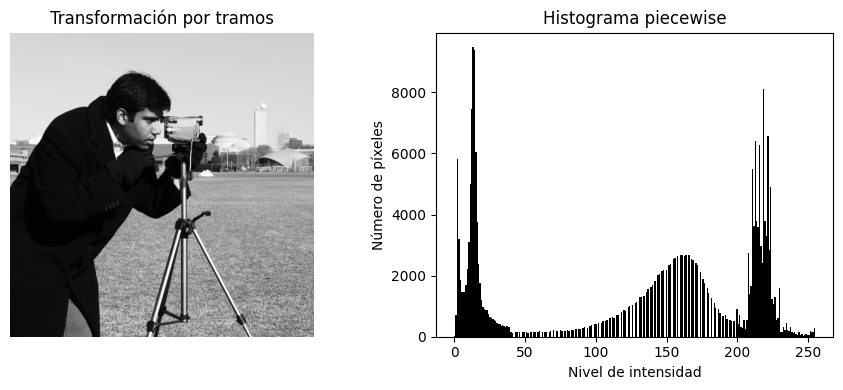

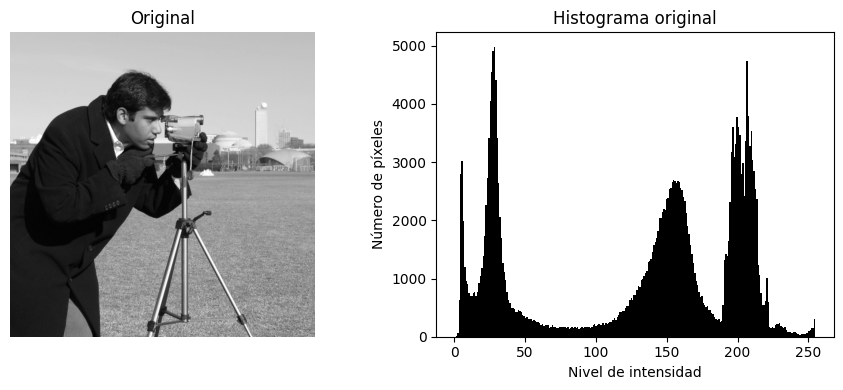

In [4]:
img_piecewise = transform_piecewise(img_gris, p1=(80, 40), p2=(180, 200))

mostrar_imagen_e_histograma(
    img_piecewise, cmap="gray",
    titulo_img="Transformación por tramos",
    titulo_hist="Histograma piecewise",
)

# Para comparar, mostramos también la imagen original
mostrar_imagen_e_histograma(
    img_gris, cmap="gray",
    titulo_img="Original",
    titulo_hist="Histograma original",
)


**Interpretación:**

El histograma se "estira" en los extremos: las sombras (valores bajos) se
concentran hacia valores aún más bajos, y las luces (valores altos) se
empujan hacia valores más altos, mientras que los tonos medios cambian
poco. El resultado visual es una imagen con **más contraste aparente**,
porque separa mejor las zonas oscuras de las claras, sin tocar demasiado
el rango medio.


## Ejercicio 4: Inversión de intensidades

$$I' = 255 - I$$


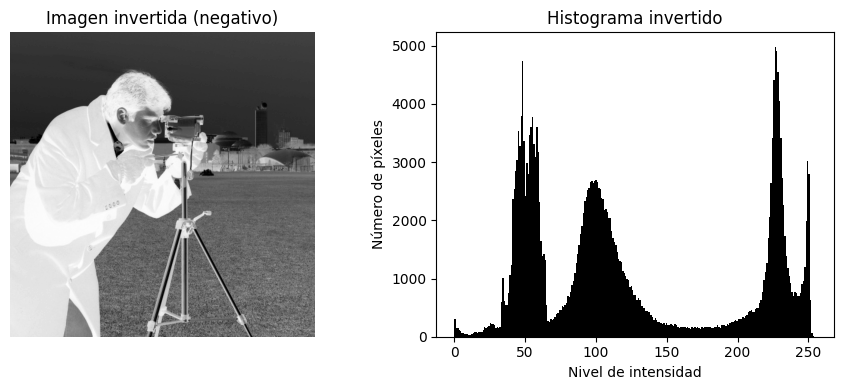

In [5]:
img_invertida = invertir(img_gris)
mostrar_imagen_e_histograma(
    img_invertida, cmap="gray",
    titulo_img="Imagen invertida (negativo)",
    titulo_hist="Histograma invertido",
)


**Interpretación:**

Esta transformación produce el **negativo** de la imagen. Se benefician
sobre todo imágenes médicas (como radiografías o mamografías), donde a
veces es más fácil detectar detalles finos en el negativo que en la
imagen original. El histograma queda **reflejado (espejado)**: lo que
antes era el extremo izquierdo (sombras) ahora es el extremo derecho
(luces), y viceversa.


# Parte 2: Transformaciones no lineales (Gamma)

## Ejercicio 5: Corrección gamma

$$I' = c \cdot I^{\gamma}$$

Probamos con $\gamma < 1$ (aclara sombras) y $\gamma > 1$ (oscurece).


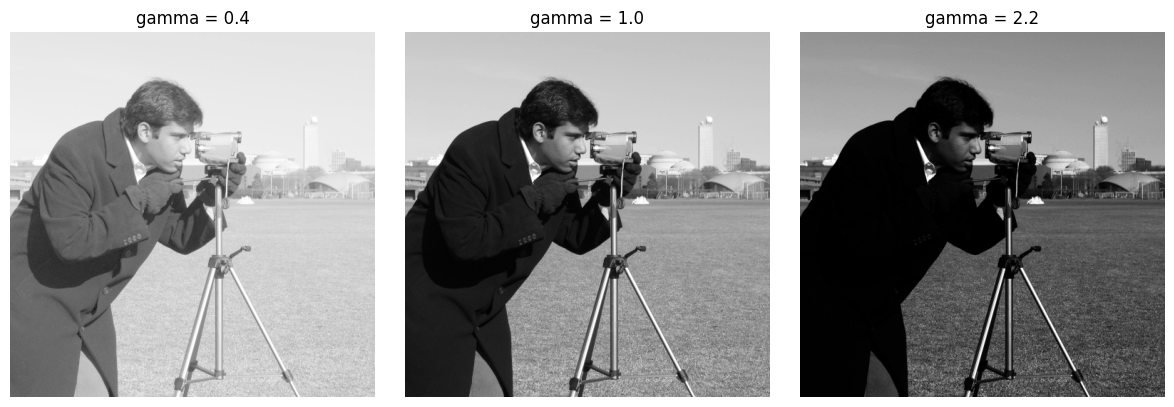

In [6]:
gammas = [0.4, 1.0, 2.2]  # <1, =1 (referencia), >1

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for i, g in enumerate(gammas):
    resultado = correccion_gamma(img_gris, gamma=g)
    ax[i].imshow(resultado, cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(f"gamma = {g}")
    ax[i].axis("off")
plt.tight_layout()
plt.show()


**Interpretación:**

Con **gamma < 1** la imagen se aclara, sobre todo en las **zonas oscuras**
(se "abren" las sombras y se ven más detalles en ellas). Con **gamma > 1**
ocurre lo contrario: la imagen se oscurece y se pierden detalles en
sombras, pero se resaltan más las diferencias entre tonos claros. Esto
tiene que ver con cómo el ojo humano percibe el brillo de forma no
lineal (percepción logarítmica), por eso gamma es tan usado para "corregir"
imágenes antes de mostrarlas en pantalla.


## Ejercicio 6: Gamma vs transformación lineal

Buscamos una transformación lineal que se "parezca" visualmente a una
transformación gamma.


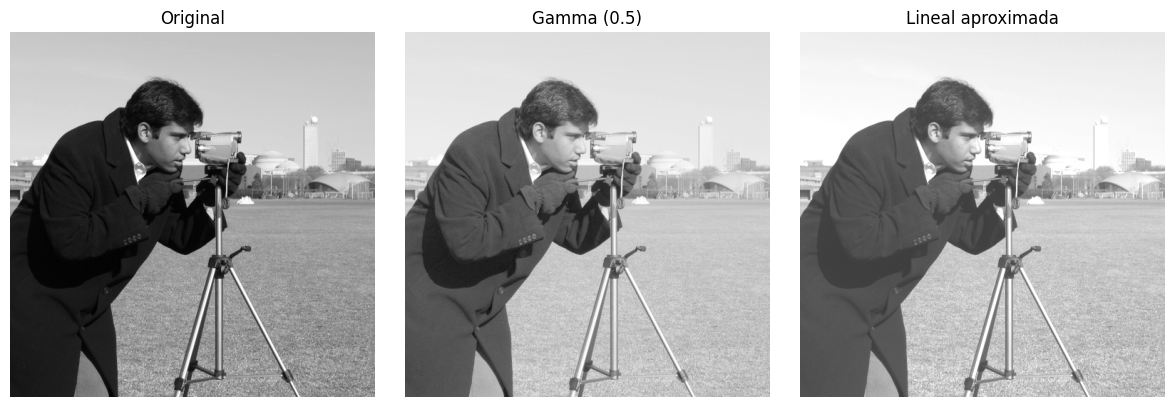

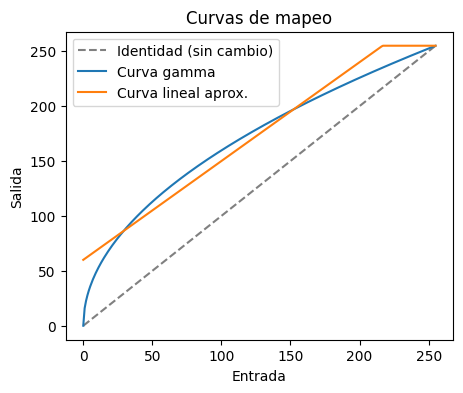

In [7]:
gamma_val = 0.5
img_gamma = correccion_gamma(img_gris, gamma=gamma_val)

# Aproximación lineal: ajustamos (a, b) a ojo para que el brillo medio
# y el rango se parezcan al resultado de la gamma
img_lineal_aprox = transform_lineal(img_gris, a=0.9, b=60, modo="clip")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img_gris, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(img_gamma, cmap="gray", vmin=0, vmax=255); ax[1].set_title(f"Gamma ({gamma_val})"); ax[1].axis("off")
ax[2].imshow(img_lineal_aprox, cmap="gray", vmin=0, vmax=255); ax[2].set_title("Lineal aproximada"); ax[2].axis("off")
plt.tight_layout()
plt.show()

# Comparamos las dos curvas de mapeo (entrada vs salida) para verlo numéricamente
x = np.arange(256)
curva_gamma = 255 * (x/255.0)**gamma_val
curva_lineal = np.clip(0.9*x + 60, 0, 255)

plt.figure(figsize=(5,4))
plt.plot(x, x, "--", color="gray", label="Identidad (sin cambio)")
plt.plot(x, curva_gamma, label="Curva gamma")
plt.plot(x, curva_lineal, label="Curva lineal aprox.")
plt.xlabel("Entrada"); plt.ylabel("Salida"); plt.legend()
plt.title("Curvas de mapeo")
plt.show()


**Interpretación:**

Visualmente se puede conseguir una aproximación razonable en una parte del
rango, pero la transformación lineal **nunca puede igualar exactamente**
a la curva gamma, porque una es una **recta** (pendiente constante en todo
el rango) y la otra es una **curva** (pendiente distinta en sombras que en
luces). Por eso, al graficar ambas curvas de mapeo, se ve que solo se
cruzan en un par de puntos, y en el resto del rango se separan.


## Ejercicio 7: Mejora de imágenes oscuras

Comparamos transformación lineal vs corrección gamma sobre una imagen
oscura.


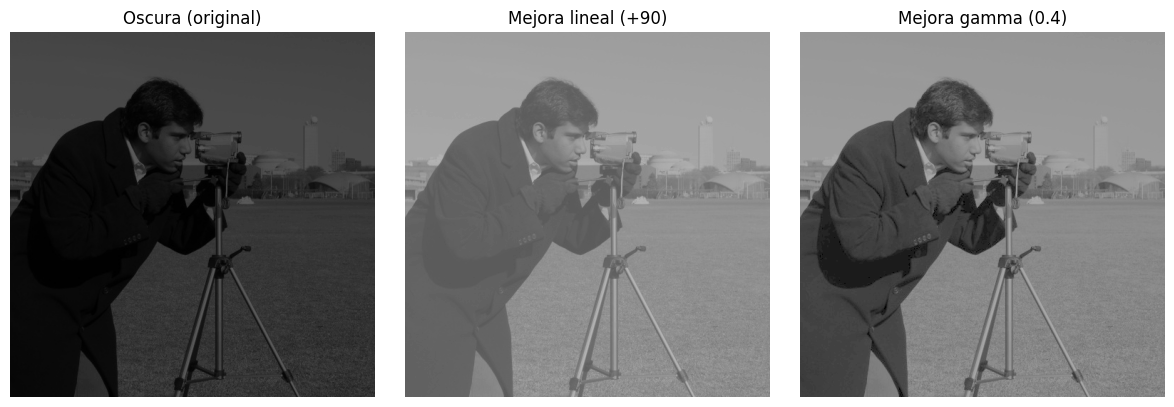

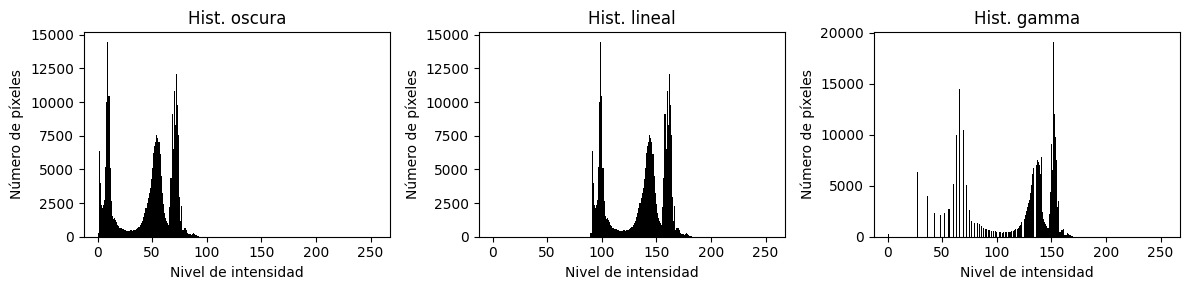

In [8]:
img_lineal_mejora = transform_lineal(img_oscura, a=1.0, b=90, modo="clip")
img_gamma_mejora = correccion_gamma(img_oscura, gamma=0.4)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img_oscura, cmap="gray", vmin=0, vmax=255); ax[0].set_title("Oscura (original)"); ax[0].axis("off")
ax[1].imshow(img_lineal_mejora, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Mejora lineal (+90)"); ax[1].axis("off")
ax[2].imshow(img_gamma_mejora, cmap="gray", vmin=0, vmax=255); ax[2].set_title("Mejora gamma (0.4)"); ax[2].axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
histograma_gris(img_oscura, ax=ax[0], titulo="Hist. oscura")
histograma_gris(img_lineal_mejora, ax=ax[1], titulo="Hist. lineal")
histograma_gris(img_gamma_mejora, ax=ax[2], titulo="Hist. gamma")
plt.tight_layout()
plt.show()


**Interpretación:**

La corrección **gamma conserva mejor los detalles en sombras**: como su
curva es más "empinada" justo en la zona oscura, logra separar mejor los
tonos que estaban muy apretados cerca de 0. La transformación **lineal**
simplemente desplaza todo por igual (suma una constante), así que aclara
la imagen pero no logra "abrir" tanto el detalle que había comprimido en
las sombras — de hecho puede saturar antes las zonas ya claras.


# Parte 3: Transformaciones en imágenes RGB

En una imagen RGB cada píxel tiene tres canales (R, G, B). Las mismas
ideas de transformación lineal y gamma se pueden aplicar a **cada canal
por separado**, lo que además de cambiar brillo/contraste permite cambiar
el **color** general de la imagen.


## Ejercicio 8: Transformación lineal independiente por canal


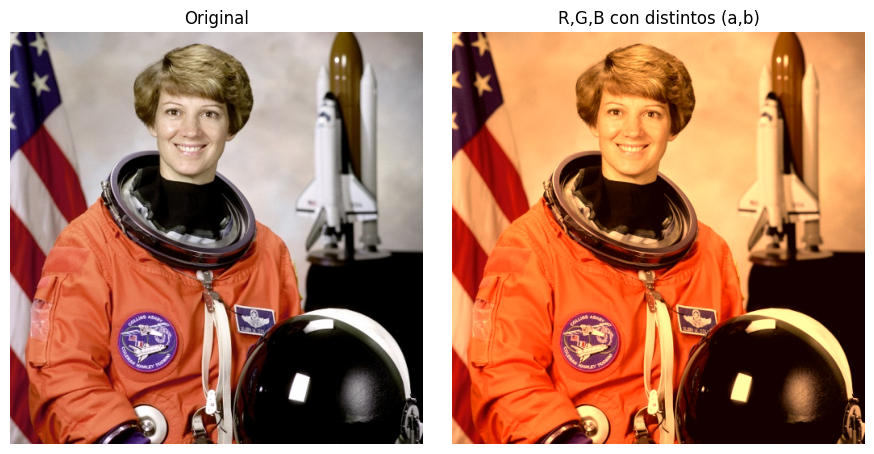

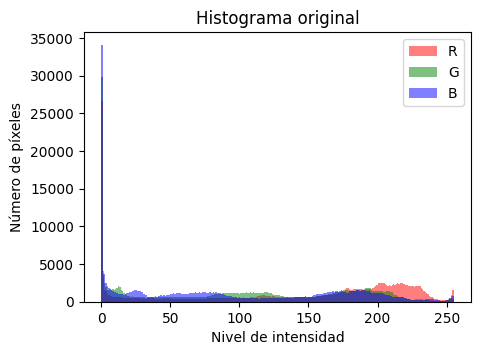

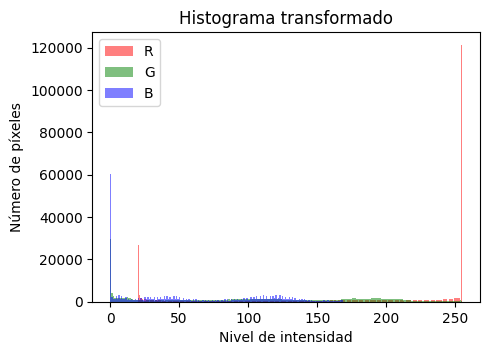

In [9]:
params = {"R": (1.3, 20), "G": (1.0, 0), "B": (0.7, -10)}
img_canales = transform_lineal_por_canal(img_color, params)

mostrar_par(img_color, img_canales, titulo_izq="Original", titulo_der="R,G,B con distintos (a,b)")
histogramas_rgb(img_color, titulo="Histograma original")
plt.show()
histogramas_rgb(img_canales, titulo="Histograma transformado")
plt.show()


**Interpretación:**

Al subir `a` y `b` en el canal **R** y bajarlos en **B**, la imagen se ve
con un tono más **cálido / rojizo-anaranjado**. El canal que más se
amplifica (en este caso R) es el que termina **dominando** la apariencia
final de color, y se nota claramente en cómo se desplaza su histograma
hacia la derecha respecto a los otros dos canales.


## Ejercicio 9: Transformación sobre un solo canal (rojo)


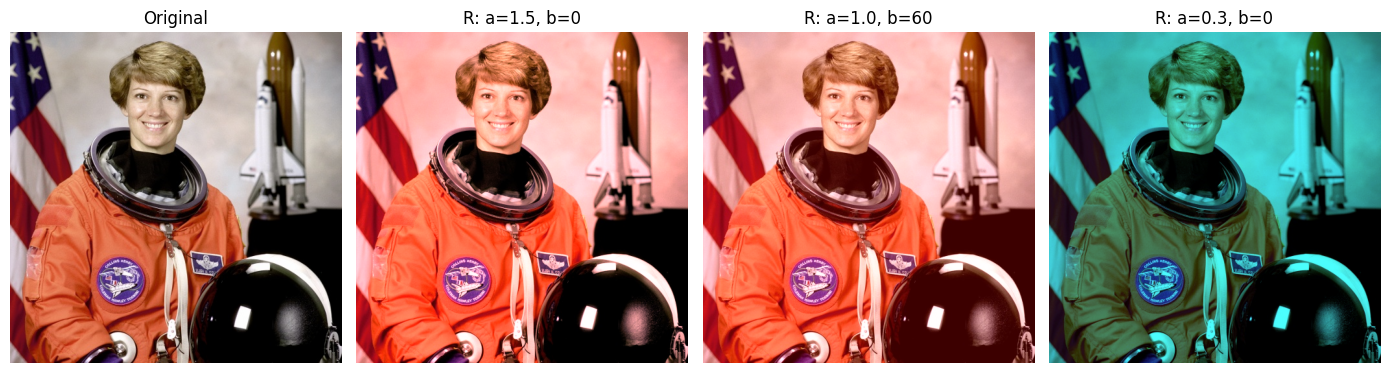

In [10]:
pruebas = [(1.5, 0), (1.0, 60), (0.3, 0)]

fig, ax = plt.subplots(1, len(pruebas)+1, figsize=(14, 4))
ax[0].imshow(img_color); ax[0].set_title("Original"); ax[0].axis("off")
for i, (a, b) in enumerate(pruebas):
    resultado = transform_canal_unico(img_color, "R", a=a, b=b)
    ax[i+1].imshow(resultado)
    ax[i+1].set_title(f"R: a={a}, b={b}")
    ax[i+1].axis("off")
plt.tight_layout()
plt.show()


**Interpretación:**

Al mover solo el canal R, la imagen se **tiñe de rojo/naranja** sin que
cambien los demás colores base. Con `a > 1` el rojo existente se
intensifica (más saturado y dominante); con `b > 0` se suma rojo de forma
pareja a toda la imagen, incluso en zonas donde antes casi no había rojo,
por lo que el efecto se parece más a un "velo" rojizo uniforme que a un
aumento de saturación.


## Ejercicio 10: Eliminación de un canal


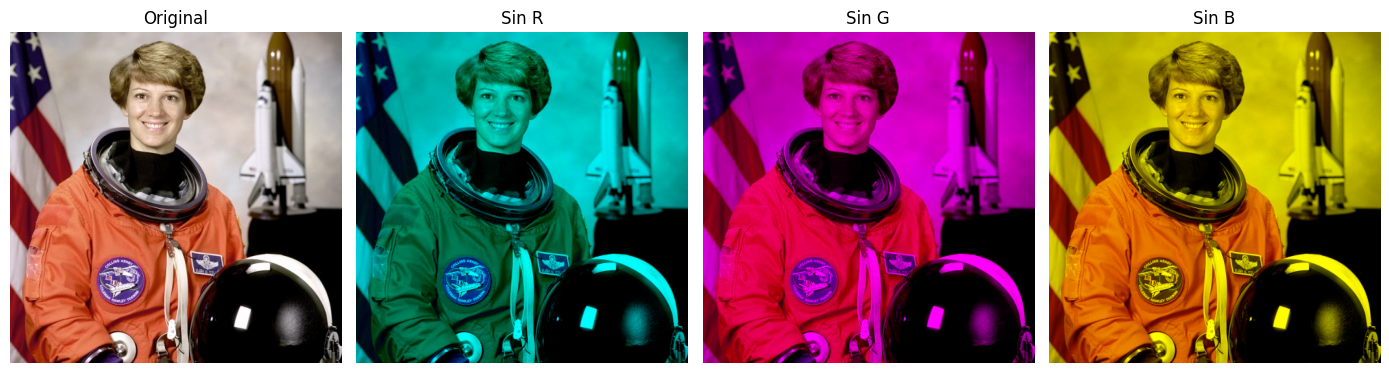

In [11]:
sin_R = eliminar_canal(img_color, "R")
sin_G = eliminar_canal(img_color, "G")
sin_B = eliminar_canal(img_color, "B")

fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for a, im, t in zip(ax, [img_color, sin_R, sin_G, sin_B], ["Original", "Sin R", "Sin G", "Sin B"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()


**Interpretación:**

Al poner un canal en cero, **desaparecen todos los colores que dependían
de ese canal** para formarse: por ejemplo, sin R desaparecen los rojos,
amarillos y magentas (que se forman combinando R con G y/o B). Lo que
**permanece** son las combinaciones de los dos canales restantes: sin R
queda dominado por tonos cian/verde-azulado (mezcla de G y B).


## Ejercicio 11: Corrección gamma por canal


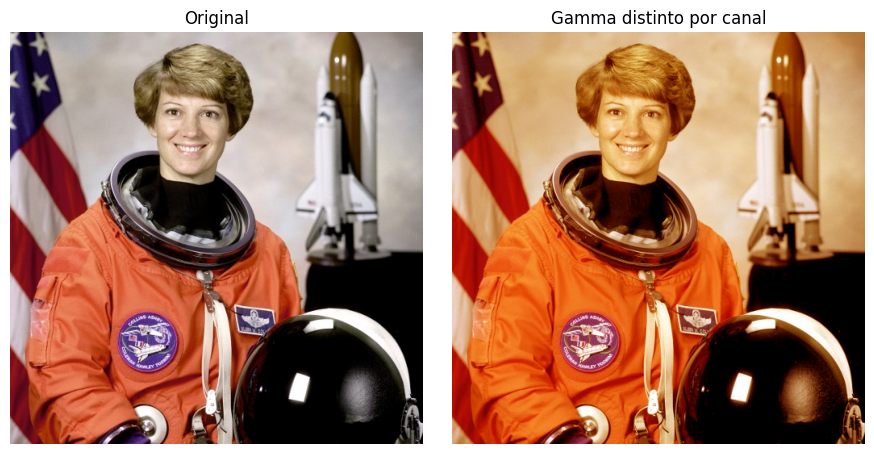

In [12]:
img_gamma_canales = gamma_por_canal(img_color, gamma_r=0.5, gamma_g=1.0, gamma_b=1.8)
mostrar_par(img_color, img_gamma_canales, titulo_izq="Original", titulo_der="Gamma distinto por canal")


**Interpretación:**

Usar un gamma distinto por canal cambia la **tonalidad global** de la
imagen: aclarar mucho el canal R (gamma bajo) y oscurecer el canal B
(gamma alto) hace que la imagen se vea con una **dominancia cálida**
(rojiza/amarillenta), porque el rojo se vuelve relativamente más fuerte
frente al azul en casi todos los píxeles. En general, cuando los gammas
de los tres canales son distintos, siempre se genera algún tipo de
dominancia de color.


## Ejercicio 12: Intercambio de canales


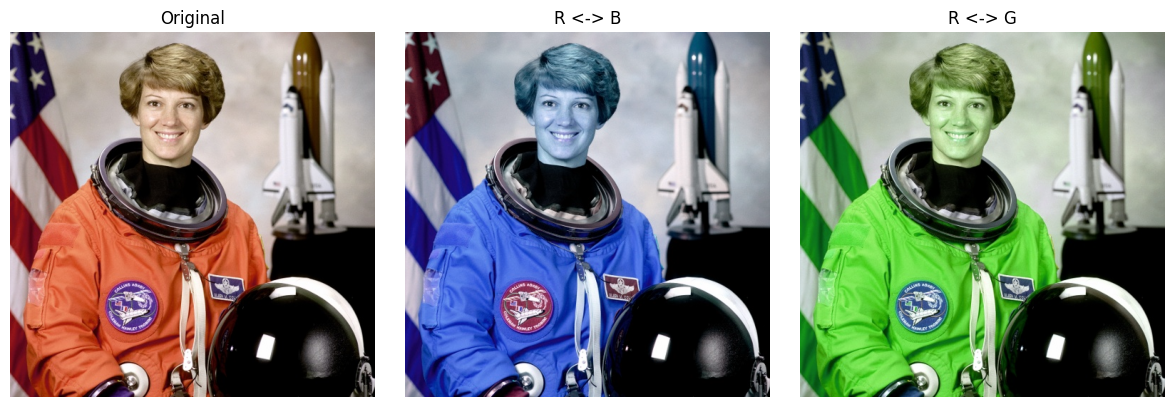

In [13]:
img_rb = intercambiar_canales(img_color, "R", "B")
img_rg = intercambiar_canales(img_color, "R", "G")

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img_color); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(img_rb); ax[1].set_title("R <-> B"); ax[1].axis("off")
ax[2].imshow(img_rg); ax[2].set_title("R <-> G"); ax[2].axis("off")
plt.tight_layout()
plt.show()


**Interpretación:**

Intercambiar canales cambia por completo la interpretación de la escena:
zonas que eran rojas pasan a verse azules (o verdes), y viceversa, aunque
la **estructura/forma** de la imagen (bordes, texturas) se mantiene igual.
Esto muestra que en RGB el **color** y la **forma** están codificados de
manera relativamente independiente: el orden/asignación de los canales
solo afecta cómo se interpreta el color, no la geometría de la escena.


## Ejercicio 13: Conversión a escala de grises vs manipulación RGB


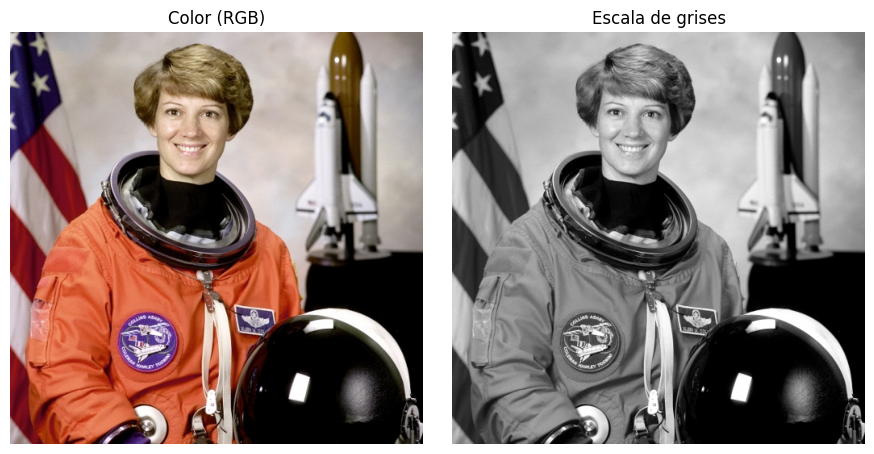

In [14]:
img_a_grises = a_escala_grises(img_color)

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(img_color); ax[0].set_title("Color (RGB)"); ax[0].axis("off")
ax[1].imshow(img_a_grises, cmap="gray", vmin=0, vmax=255); ax[1].set_title("Escala de grises"); ax[1].axis("off")
plt.tight_layout()
plt.show()


**Interpretación:**

Al convertir a escala de grises se **pierde toda la información de
color** (matiz y saturación): la imagen en gris solo conserva la
luminancia (qué tan "clara" u "oscura" se ve cada zona), calculada como
una combinación ponderada de R, G y B. Dos colores distintos pero con
luminancia parecida (por ejemplo un rojo y un verde de brillo similar)
pueden terminar viéndose **igual** en escala de grises, aunque en la
imagen original eran muy distinguibles.


## Ejercicio 14: Análisis de histogramas por canal


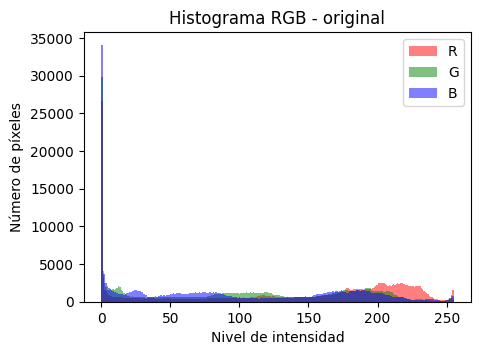

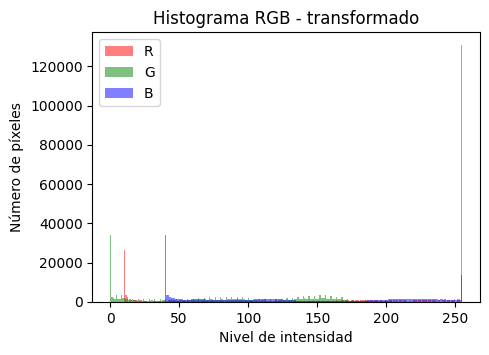

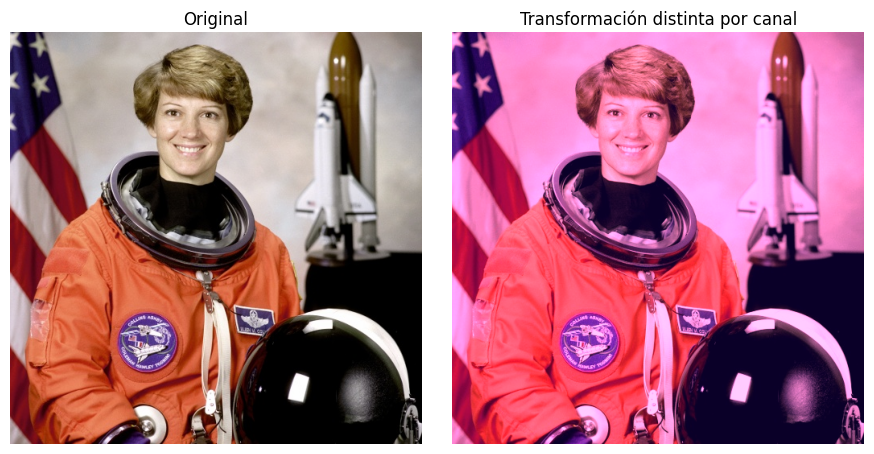

In [15]:
# Histogramas de la imagen original
histogramas_rgb(img_color, titulo="Histograma RGB - original")
plt.show()

# Aplicamos una transformación DISTINTA a cada canal
img_distinta_por_canal = transform_lineal_por_canal(
    img_color, {"R": (1.4, 10), "G": (0.8, 0), "B": (1.0, 40)}
)

histogramas_rgb(img_distinta_por_canal, titulo="Histograma RGB - transformado")
plt.show()

mostrar_par(img_color, img_distinta_por_canal, titulo_izq="Original", titulo_der="Transformación distinta por canal")


**Interpretación:**

Cada histograma se desplaza de forma distinta según la transformación que
recibió su canal: el canal R se estira y se mueve a la derecha (más
contraste y brillo), el canal G se comprime hacia la izquierda (menos
contraste), y el canal B se desplaza en bloque hacia la derecha (más
brillo, mismo contraste). El **color percibido** de la imagen resulta de
la combinación, píxel a píxel, de en qué posición relativa quedó cada
canal: si un canal domina el histograma (tiene valores más altos en
promedio que los otros), ese color tiende a predominar visualmente.


## Ejercicio 15: Diseño de estilo visual

Diseñamos transformaciones para lograr efectos de imagen "cálida", "fría"
y de "alto contraste".


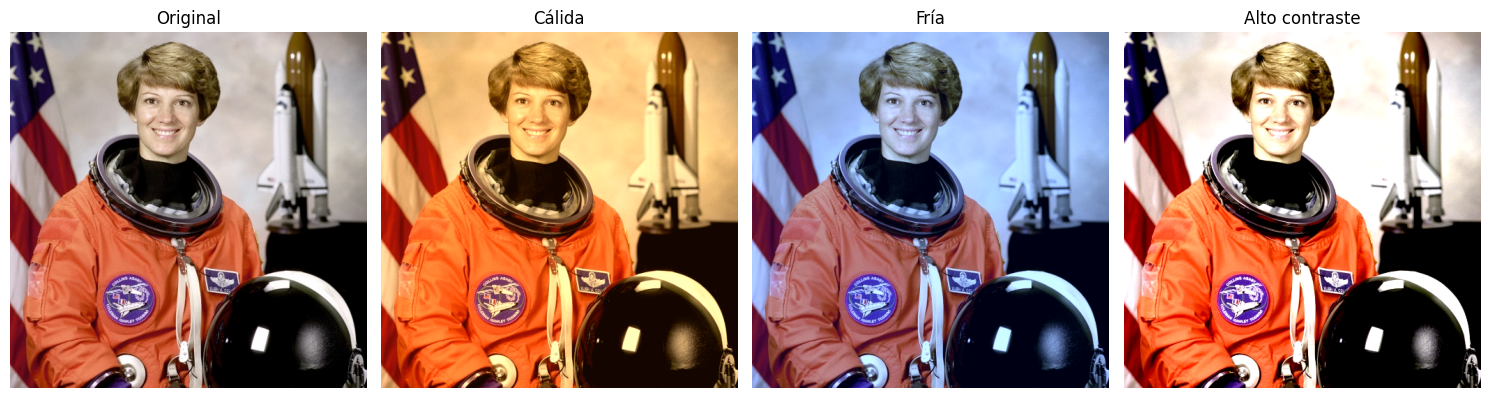

In [16]:
# Cálida: sube R, baja un poco B
img_calida = transform_lineal_por_canal(img_color, {"R": (1.2, 20), "G": (1.05, 5), "B": (0.8, -15)})

# Fría: sube B, baja un poco R
img_fria = transform_lineal_por_canal(img_color, {"R": (0.85, -10), "G": (1.0, 0), "B": (1.25, 20)})

# Alto contraste: mismo (a,b) fuerte en los 3 canales
img_alto_contraste = transform_lineal_por_canal(img_color, {"R": (1.6, -50), "G": (1.6, -50), "B": (1.6, -50)})

fig, ax = plt.subplots(1, 4, figsize=(15, 4.5))
for a, im, t in zip(ax, [img_color, img_calida, img_fria, img_alto_contraste],
                     ["Original", "Cálida", "Fría", "Alto contraste"]):
    a.imshow(im); a.set_title(t); a.axis("off")
plt.tight_layout()
plt.show()


**Justificación de los parámetros:**

- **Cálida:** se aumenta `a` y `b` del canal R (más rojo) y se reduce el
  canal B (menos azul), imitando la luz de atardecer/tungsteno.
- **Fría:** al revés — se reduce R y se aumenta B, imitando luz de día
  nublado o sombra.
- **Alto contraste:** se usa el mismo `a` grande (>1) en los 3 canales
  para separar más los tonos claros de los oscuros, y un `b` negativo
  para compensar y que la imagen no quede sobreexpuesta, manteniendo el
  balance de color original (mismos parámetros en R, G y B).


## Conclusión general

A lo largo de estos ejercicios se vio cómo transformaciones matemáticas
simples (lineales y gamma) sobre los valores de intensidad permiten
controlar brillo, contraste, color y realce de detalles en distintas
zonas tonales de una imagen. La elección entre clipping y normalización,
o entre transformación lineal y gamma, depende del efecto que se busque y
de si la imagen tiene zonas muy oscuras o muy claras que se quieran
recuperar.


